In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

# Define the file path from your Google Drive
zip_file_path = '/content/drive/My Drive/FALL26/INFO4604 - Applied Machine Learning/horror_movies.csv.zip'

# Load the zipped CSV directly into a pandas DataFrame
df = pd.read_csv(zip_file_path)

# Display the first few rows to confirm it loaded correctly
display(df.head())

,id,original_title,title,original_language,overview,tagline,release_date,poster_path,popularity,vote_count,vote_average,budget,revenue,runtime,status,adult,backdrop_path,genre_names,collection,collection_name
0,760161,Orphan: First Kill,Orphan: First Kill,en,After escaping from an Estonian psychiatric fa...,There's always been something wrong with Esther.,2022-07-27,/pHkKbIRoCe7zIFvqan9LFSaQAde.jpg,5088.584,902,6.9,0,9572765,99,Released,False,/5GA3vV1aWWHTSDO5eno8V5zDo8r.jpg,"Horror, Thriller",760193.0,Orphan Collection
1,760741,Beast,Beast,en,A recently widowed man and his two teenage dau...,Fight for family.,2022-08-11,/xIGr7UHsKf0URWmyyd5qFMAq4d8.jpg,2172.338,584,7.1,0,56000000,93,Released,False,/2k9tBql5GYH328Krj66tDT9LtFZ.jpg,"Adventure, Drama, Horror",NaN,NaN
2,882598,Smile,Smile,en,"After witnessing a bizarre, traumatic incident...","Once you see it, it’s too late.",2022-09-23,/hiaeZKzwsk4y4atFhmncO5KRxeT.jpg,1863.628,114,6.8,17000000,45000000,115,Released,False,/mVNPfpydornVe4H4UCIk7WevWjf.jpg,"Horror, Mystery, Thriller",NaN,NaN
3,756999,The Black Phone,The Black Phone,en,"Finney Blake, a shy but clever 13-year-old boy...",Never talk to strangers.,2022-06-22,/lr11mCT85T1JanlgjMuhs9nMht4.jpg,1071.398,2736,7.9,18800000,161000000,103,Released,False,/AfvIjhDu9p64jKcmohS4hsPG95Q.jpg,"Horror, Thriller",NaN,NaN
4,772450,Presencias,Presences,es,A man who loses his wife and goes to seclude h...,NaN,2022-09-07,/dgDT3uol3mdvwEg0jt1ble3l9hw.jpg,1020.995,83,7.0,0,0,0,Released,False,/ojfzhdwRemcDt1I6pao6vVLw9AA.jpg,Horror,NaN,NaN


In [ ]:
df.head()
df.shape
df.info()          # column types + non-null counts
df.describe()
df.isnull().sum()  # how much is missing, per column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32540 entries, 0 to 32539
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 32540 non-null  int64  
 1   original_title     32540 non-null  object 
 2   title              32540 non-null  object 
 3   original_language  32540 non-null  object 
 4   overview           31254 non-null  object 
 5   tagline            12706 non-null  object 
 6   release_date       32540 non-null  object 
 7   poster_path        28066 non-null  object 
 8   popularity         32540 non-null  float64
 9   vote_count         32540 non-null  int64  
 10  vote_average       32540 non-null  float64
 11  budget             32540 non-null  int64  
 12  revenue            32540 non-null  int64  
 13  runtime            32540 non-null  int64  
 14  status             32540 non-null  object 
 15  adult              32540 non-null  bool   
 16  backdrop_path      135

,0
id,0
original_title,0
title,0
original_language,0
overview,1286
tagline,19834
release_date,0
poster_path,4474
popularity,0
vote_count,0



# I want to figure out how different horror genres affect a movie's popularity in this database.

In [ ]:
# drop the columns 'overview', 'tagline', 'poster_path', 'backdrop_path', 'collection', 'collection_name'
columns_to_drop = ['overview', 'tagline', 'poster_path', 'backdrop_path', 'collection', 'collection_name', 'adult']
df = df.drop(columns=columns_to_drop, errors='ignore')

# Display the new shape and columns of the DataFrame
print(f"New shape: {df.shape}")
display(df.head())

New shape: (32540, 13)


,id,original_title,title,original_language,release_date,popularity,vote_count,vote_average,budget,revenue,runtime,status,genre_names
0,760161,Orphan: First Kill,Orphan: First Kill,en,2022-07-27,5088.584,902,6.9,0,9572765,99,Released,"Horror, Thriller"
1,760741,Beast,Beast,en,2022-08-11,2172.338,584,7.1,0,56000000,93,Released,"Adventure, Drama, Horror"
2,882598,Smile,Smile,en,2022-09-23,1863.628,114,6.8,17000000,45000000,115,Released,"Horror, Mystery, Thriller"
3,756999,The Black Phone,The Black Phone,en,2022-06-22,1071.398,2736,7.9,18800000,161000000,103,Released,"Horror, Thriller"
4,772450,Presencias,Presences,es,2022-09-07,1020.995,83,7.0,0,0,0,Released,Horror


Check Class Imbalence

The class balance will be about 90/10

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32540 entries, 0 to 32539
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 32540 non-null  int64  
 1   original_title     32540 non-null  object 
 2   title              32540 non-null  object 
 3   original_language  32540 non-null  object 
 4   release_date       32540 non-null  object 
 5   popularity         32540 non-null  float64
 6   vote_count         32540 non-null  int64  
 7   vote_average       32540 non-null  float64
 8   budget             32540 non-null  int64  
 9   revenue            32540 non-null  int64  
 10  runtime            32540 non-null  int64  
 11  status             32540 non-null  object 
 12  genre_names        32540 non-null  object 
dtypes: float64(2), int64(5), object(6)
memory usage: 3.2+ MB


In [ ]:
df['genre_names'].head()

,genre_names
0,"Horror, Thriller"
1,"Adventure, Drama, Horror"
2,"Horror, Mystery, Thriller"
3,"Horror, Thriller"
4,Horror


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [ ]:
# Split first, then define the cutoff from TRAIN only (replacing 'horror' with 'df')
train, test = train_test_split(df, test_size=0.2, random_state=42)
cutoff = train['popularity'].quantile(0.90)

# Create a copy to prevent SettingWithCopyWarning
train = train.copy()
test = test.copy()

# Safely extract release_year from release_date for both train and test sets
for d in (train, test):
    d['release_date'] = pd.to_datetime(d['release_date'], errors='coerce')
    d['release_year'] = d['release_date'].dt.year
    d['is_highly_popular'] = (d['popularity'] >= cutoff).astype(int)

print(train['is_highly_popular'].value_counts())
print(train['is_highly_popular'].value_counts(normalize=True) * 100)
print(f"Cutoff (train 90th pct, horror only): {cutoff:.2f}")

is_highly_popular
0    23427
1     2605
Name: count, dtype: int64
is_highly_popular
0    89.993085
1    10.006915
Name: proportion, dtype: float64
Cutoff (train 90th pct, horror only): 6.48


Creating histogram visuals

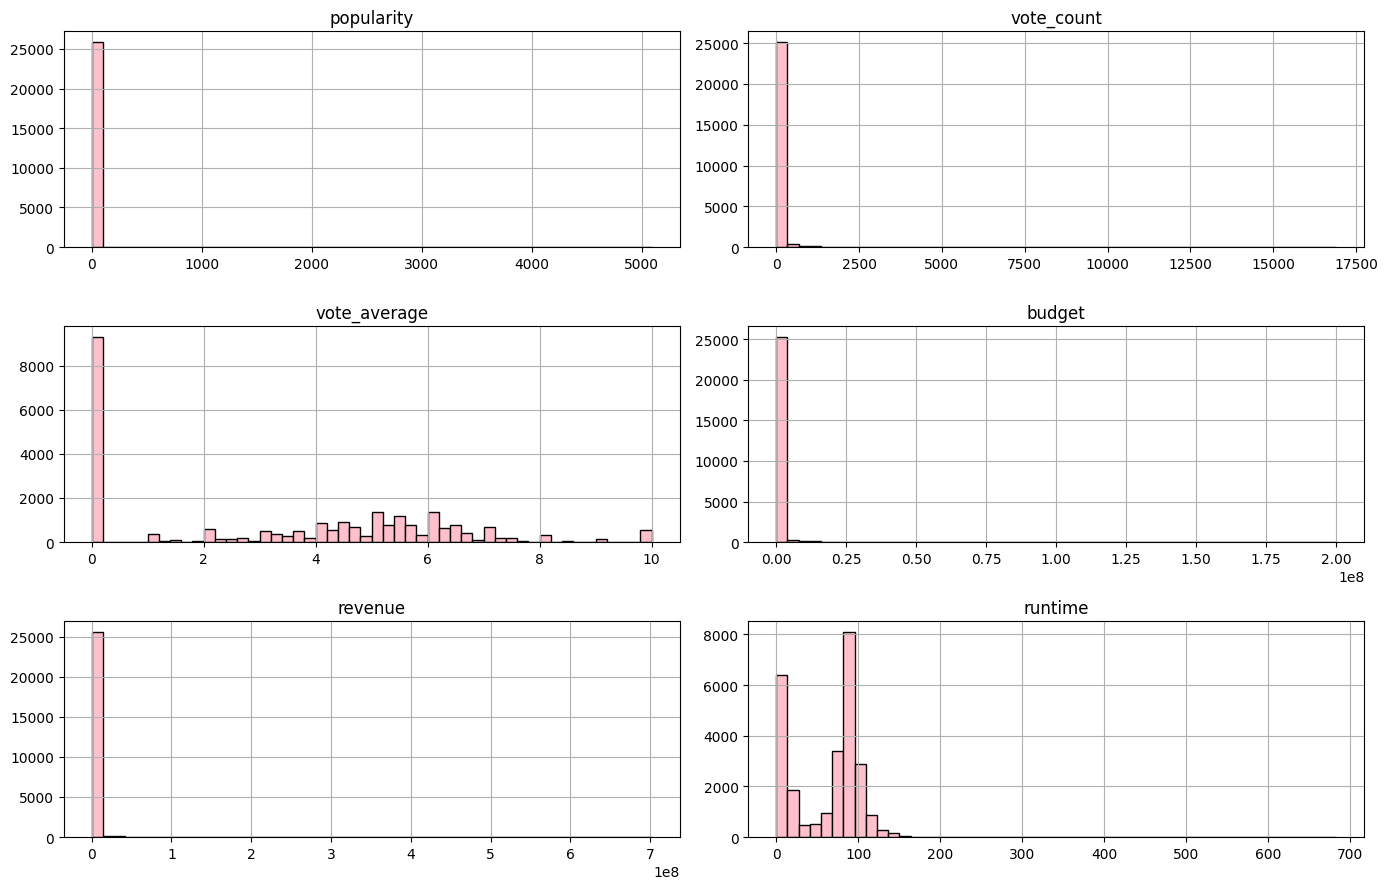

                count          mean           std  min   1%      50%  \
popularity    26032.0  4.163611e+00  4.113088e+01  0.0  0.6   0.8395   
vote_count    26032.0  6.244637e+01  4.153430e+02  0.0  0.0   2.0000   
vote_average  26032.0  3.341280e+00  2.883678e+00  0.0  0.0   4.0000   
budget        26032.0  5.453664e+05  4.585114e+06  0.0  0.0   0.0000   
revenue       26032.0  1.388744e+06  1.515206e+07  0.0  0.0   0.0000   
runtime       26032.0  6.216130e+01  4.115439e+01  0.0  0.0  80.0000   

                       99%           max  
popularity    4.842949e+01  5.088584e+03  
vote_count    1.401660e+03  1.690000e+04  
vote_average  1.000000e+01  1.000000e+01  
budget        1.500000e+07  2.000000e+08  
revenue       3.768757e+07  7.018426e+08  
runtime       1.380000e+02  6.830000e+02  


In [ ]:
num_cols = ['popularity', 'vote_count', 'vote_average', 'budget', 'revenue', 'runtime']

train[num_cols].hist(bins=50, figsize=(14, 9), edgecolor='black', color='pink')
plt.tight_layout()
plt.show()

print(train[num_cols].describe(percentiles=[.01, .5, .99]).T)

We can't delete high popularity or high budget movies because they’re real and are exactly what i'm looking for. I will Log-transform the skewed columns instead

In [ ]:
# log-transform the skewed columns
from sklearn.preprocessing import FunctionTransformer
log_transformer = FunctionTransformer(np.log1p, validate=True)

train[num_cols] = log_transformer.transform(train[num_cols])
test[num_cols] = log_transformer.transform(test[num_cols])


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but FunctionTransformer was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but FunctionTransformer was fitted without feature names
  warnings.warn(


Removing impossible values

In [ ]:
train = train[(train['runtime'].between(1, 300) | (train['runtime'] == 0))]

In [ ]:
q1, q3 = train['runtime'].quantile([.25, .75]); iqr = q3 - q1
train = train[train['runtime'].between(q1 - 3*iqr, q3 + 3*iqr) | (train['runtime'] == 0)]

In [ ]:
train

,id,original_title,title,original_language,release_date,popularity,vote_count,vote_average,budget,revenue,runtime,status,genre_names,release_year,is_highly_popular
19916,231994,The Mistake,The Mistake,en,2012-02-01,0.470004,0.693147,1.791759,0.000000,0.000000,1.609438,Released,"Comedy, Horror",2012,0
32495,1030647,In the Ruins,In the Ruins,en,2016-02-10,0.470004,0.000000,0.000000,0.000000,0.000000,0.000000,Released,Horror,2016,0
11947,741616,A Night in Camp Heebie Jeebie,A Night in Camp Heebie Jeebie,en,2020-08-28,0.875469,0.000000,0.000000,0.000000,0.000000,1.945910,Released,"Animation, Comedy, Horror",2020,0
5455,339992,The Redwood Massacre,The Redwood Massacre,en,2014-09-28,1.525839,3.871201,1.648659,11.961840,0.000000,4.418841,Released,Horror,2014,0
27553,735979,Evil Under the Skin,Evil Under the Skin,en,2019-06-01,0.470004,0.000000,0.000000,0.000000,0.000000,4.510860,Released,"Horror, Thriller",2019,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29802,852262,Redrat: La Rata Retobada,Redrat: The Rebellious Rodent,es,2005-05-12,0.470004,0.000000,0.000000,5.993961,0.000000,3.044522,Released,"Animation, Horror",2005,0
5390,811061,So Cold the River,So Cold the River,en,2022-03-25,1.536437,2.397895,1.547563,0.000000,0.000000,4.543295,Released,"Horror, Thriller",2022,0
860,6933,One Missed Call,One Missed Call,en,2008-01-04,3.061099,6.472346,1.856298,16.811243,17.640837,4.477337,Released,"Horror, Mystery, Thriller",2008,1
15795,738162,Broken Contact - A Poltergeist Story,Broken Contact - A Poltergeist Story,en,2020-08-28,0.622188,0.000000,0.000000,0.000000,0.000000,4.369448,Released,"Documentary, Horror",2020,0


Impute missing values

In [ ]:
for d in (train, test):
    d[['budget', 'revenue', 'runtime']] = d[['budget', 'revenue', 'runtime']].replace(0, np.nan)

# Calculate missing percentages including release_year
print(train[['budget', 'revenue', 'runtime', 'release_year']].isna().mean() * 100)

budget          83.877701
revenue         95.106490
runtime          8.267945
release_year     0.000000
dtype: float64


Since Budget and revenue have such high missing data values. The following code creates a new column budget_missing containing 1 if the budget was missing, and 0 if it was known.

 For each of these three columns, it calculates the median value of the training set. This calculates the median on the train set only. This prevents "data leakage".

 Movie budgets can be very skewed, np.log1p calculates the natural log of (1 + budget). This compresses the scale.

In [ ]:
for d in (train, test):
    d['budget_missing'] = d['budget'].isna().astype(int)

# Now imputing all three columns, including release_year
for c in ['budget', 'runtime', 'release_year']:
    med = train[c].median()
    train[c] = train[c].fillna(med)
    test[c] = test[c].fillna(med)

train['log_budget'] = np.log1p(train['budget'])
test['log_budget'] = np.log1p(test['budget'])

Encoding text fields

In [ ]:
df

,id,original_title,title,original_language,release_date,popularity,vote_count,vote_average,budget,revenue,runtime,status,genre_names
0,760161,Orphan: First Kill,Orphan: First Kill,en,2022-07-27,5088.584,902,6.9,0,9572765,99,Released,"Horror, Thriller"
1,760741,Beast,Beast,en,2022-08-11,2172.338,584,7.1,0,56000000,93,Released,"Adventure, Drama, Horror"
2,882598,Smile,Smile,en,2022-09-23,1863.628,114,6.8,17000000,45000000,115,Released,"Horror, Mystery, Thriller"
3,756999,The Black Phone,The Black Phone,en,2022-06-22,1071.398,2736,7.9,18800000,161000000,103,Released,"Horror, Thriller"
4,772450,Presencias,Presences,es,2022-09-07,1020.995,83,7.0,0,0,0,Released,Horror
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32535,1032201,Catch a Butcher,Catch a Butcher,en,2021-11-20,0.600,0,0.0,0,0,11,Released,Horror
32536,1032667,Shaye Saint John: The Triggers Compilation,Shaye Saint John: The Triggers Compilation,en,2006-10-30,0.600,0,0.0,0,0,92,Released,"Fantasy, Horror"
32537,1032890,Welcome to the Occult Forest,Welcome to the Occult Forest,en,2022-07-22,0.600,0,0.0,0,0,141,Released,"Comedy, Drama, Horror"
32538,1033052,The Mean One,The Mean One,en,2022-12-15,0.000,0,0.0,0,0,0,Post Production,Horror


In [ ]:
# drop these columns id, title, original_title

columns_to_drop = ['id', 'title', 'original_title', 'original_language']
df = df.drop(columns=columns_to_drop, errors='ignore')

In [ ]:
# print what is in the status column

print(df['status'].value_counts())

# one hot encode the status column

encoded_status = pd.get_dummies(df['status'], dtype=int)

# drop the original column
df = df.drop('status', axis=1)

# Concatenate the encoded columns with the rest of the DataFrame
df = pd.concat([df, encoded_status], axis=1)

# Print the updated DataFrame to verify the encoding
df

status
Released           32405
In Production         69
Post Production       61
Planned                5
Name: count, dtype: int64


,release_date,popularity,vote_count,vote_average,budget,revenue,runtime,genre_names,In Production,Planned,Post Production,Released
0,2022-07-27,5088.584,902,6.9,0,9572765,99,"Horror, Thriller",0,0,0,1
1,2022-08-11,2172.338,584,7.1,0,56000000,93,"Adventure, Drama, Horror",0,0,0,1
2,2022-09-23,1863.628,114,6.8,17000000,45000000,115,"Horror, Mystery, Thriller",0,0,0,1
3,2022-06-22,1071.398,2736,7.9,18800000,161000000,103,"Horror, Thriller",0,0,0,1
4,2022-09-07,1020.995,83,7.0,0,0,0,Horror,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
32535,2021-11-20,0.600,0,0.0,0,0,11,Horror,0,0,0,1
32536,2006-10-30,0.600,0,0.0,0,0,92,"Fantasy, Horror",0,0,0,1
32537,2022-07-22,0.600,0,0.0,0,0,141,"Comedy, Drama, Horror",0,0,0,1
32538,2022-12-15,0.000,0,0.0,0,0,0,Horror,0,0,1,0


In [ ]:
# to one hot encode a comma seperated text field we use the MultiLabelBinarizer from scikit-learn

import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer

# 1. Split the comma-separated string into a list of genres
genre_lists = df['genre_names'].str.split(',').apply(lambda g: [x.strip() for x in g])

# 2. Fit the binarizer and transform
mlb = MultiLabelBinarizer()
genre_encoded = pd.DataFrame(
    mlb.fit_transform(genre_lists),
    columns=mlb.classes_,
    index=df.index
)

# 3. Attach to the dataframe and drop the original text column
df = pd.concat([df.drop(columns='genre_names'), genre_encoded], axis=1)

print(genre_encoded.head())
print(genre_encoded.sum().sort_values(ascending=False))   # movies per genre

   Action  Adventure  Animation  Comedy  Crime  Documentary  Drama  Family  \
0       0          0          0       0      0            0      0       0   
1       0          1          0       0      0            0      1       0   
2       0          0          0       0      0            0      0       0   
3       0          0          0       0      0            0      0       0   
4       0          0          0       0      0            0      0       0   

   Fantasy  History  Horror  Music  Mystery  Romance  Science Fiction  \
0        0        0       1      0        0        0                0   
1        0        0       1      0        0        0                0   
2        0        0       1      0        1        0                0   
3        0        0       1      0        0        0                0   
4        0        0       1      0        0        0                0   

   TV Movie  Thriller  War  Western  
0         0         1    0        0  
1         0     

In [ ]:
df

,release_date,popularity,vote_count,vote_average,budget,revenue,runtime,In Production,Planned,Post Production,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
0,2022-07-27,5088.584,902,6.9,0,9572765,99,0,0,0,...,0,1,0,0,0,0,0,1,0,0
1,2022-08-11,2172.338,584,7.1,0,56000000,93,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2,2022-09-23,1863.628,114,6.8,17000000,45000000,115,0,0,0,...,0,1,0,1,0,0,0,1,0,0
3,2022-06-22,1071.398,2736,7.9,18800000,161000000,103,0,0,0,...,0,1,0,0,0,0,0,1,0,0
4,2022-09-07,1020.995,83,7.0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32535,2021-11-20,0.600,0,0.0,0,0,11,0,0,0,...,0,1,0,0,0,0,0,0,0,0
32536,2006-10-30,0.600,0,0.0,0,0,92,0,0,0,...,0,1,0,0,0,0,0,0,0,0
32537,2022-07-22,0.600,0,0.0,0,0,141,0,0,0,...,0,1,0,0,0,0,0,0,0,0
32538,2022-12-15,0.000,0,0.0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0


Correlation

In [ ]:
# Drop the raw string 'release_date' and compute correlation on numeric columns only
df_numeric = df.drop(columns=['release_date'], errors='ignore')

# Calculate correlation
correlation_matrix = df_numeric.corr()
display(correlation_matrix)

,popularity,vote_count,vote_average,budget,revenue,runtime,In Production,Planned,Post Production,Released,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
popularity,1.000000,0.169355,0.077265,0.115664,0.155160,0.065022,-0.001379,-0.000669,0.001033,0.000420,...,-0.000891,0.000872,0.000880,0.031085,-0.004725,0.010528,-0.001585,0.053931,0.016903,-0.001911
vote_count,0.169355,1.000000,0.152381,0.520529,0.780073,0.137960,-0.006866,-0.001847,-0.006455,0.009614,...,-0.001260,0.001566,-0.008914,0.068297,-0.003361,0.050683,-0.014013,0.094688,0.008082,-0.003764
vote_average,0.077265,0.152381,1.000000,0.101709,0.097559,0.278587,-0.053467,-0.014379,-0.050266,0.074863,...,0.009225,-0.009404,0.002890,0.093452,0.015974,0.082953,0.054944,0.154127,0.019529,0.009303
budget,0.115664,0.520529,0.101709,1.000000,0.630493,0.114139,-0.005496,-0.001482,0.009203,-0.001974,...,0.028870,0.001326,-0.001425,0.062877,0.010954,0.074152,-0.012248,0.078806,0.021258,0.010231
revenue,0.155160,0.780073,0.097559,0.630493,1.000000,0.097069,-0.004312,-0.001160,-0.004054,0.006037,...,-0.002702,0.001037,-0.008800,0.056207,-0.001404,0.036828,-0.013603,0.061298,0.005709,-0.005665
runtime,0.065022,0.137960,0.278587,0.114139,0.097069,1.000000,-0.041502,-0.013711,-0.028449,0.051490,...,0.003380,0.001932,-0.018592,0.097145,0.043468,0.082083,0.054109,0.172203,0.006368,0.015720
In Production,-0.001379,-0.006866,-0.053467,-0.005496,-0.004312,-0.041502,1.000000,-0.000571,-0.001998,-0.714193,...,0.018262,0.000511,0.002487,0.000783,0.008085,0.003008,-0.006704,0.001125,-0.002428,-0.002953
Planned,-0.000669,-0.001847,-0.014379,-0.001482,-0.001160,-0.013711,-0.000571,1.000000,-0.000537,-0.192065,...,-0.000785,0.000137,-0.001202,0.004349,-0.001740,-0.003740,-0.001803,0.010626,-0.000653,-0.000794
Post Production,0.001033,-0.006455,-0.050266,0.009203,-0.004054,-0.028449,-0.001998,-0.000537,1.000000,-0.671433,...,-0.002745,0.000481,-0.004202,-0.002124,0.004236,-0.002795,-0.001314,0.007701,-0.002282,0.008359
Released,0.000420,0.009614,0.074863,-0.001974,0.006037,0.051490,-0.714193,-0.192065,-0.671433,1.000000,...,-0.011071,-0.000716,0.001280,0.000030,-0.008301,0.000449,0.006030,-0.008037,0.003399,-0.003359


### Unsupervised Learning: Clustering Movies without using Target labels
We will extract all numerical features and dummy-encoded sub-genres, scale the metrics, and search for natural groupings using K-Means clustering.

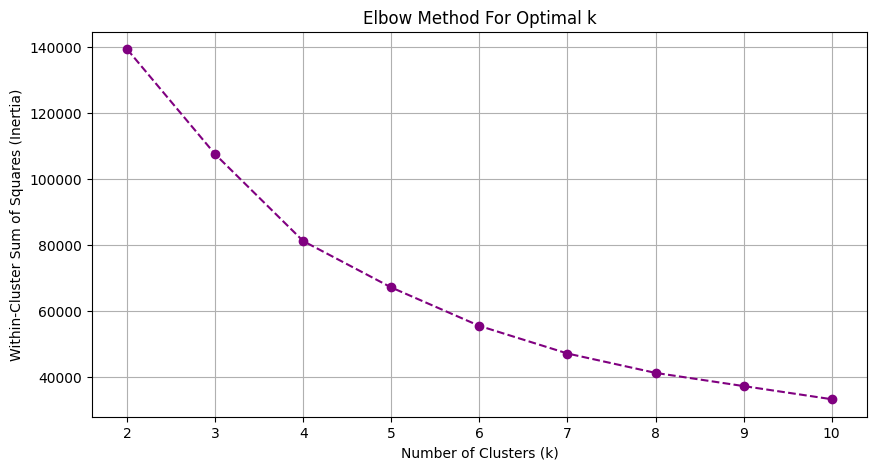

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Define feature columns (only using numeric columns and dropping targets/keys/revenue)
features_to_use = [col for col in train.select_dtypes(include=[np.number]).columns if col not in [
    'id', 'popularity', 'is_highly_popular', 'revenue'
]]

X_train_unsupervised = train[features_to_use].copy()

# 2. Scale our feature columns
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_unsupervised)

# 3. Use the Elbow Method to determine the optimal cluster count
wcss = []
k_range = range(2, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(10, 5))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='purple')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (Inertia)')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.cluster import KMeans

# 4. Run K-Means with an estimated optimal cluster count (e.g., k=4) and project with PCA
optimal_k = 4

# Dynamically select only numeric columns, excluding ID, popularity metrics, and revenue targets
k_features_to_use = [col for col in train.select_dtypes(include=[np.number]).columns if col not in [
    'id', 'popularity', 'is_highly_popular', 'revenue'
]]

X_train_clean = train[k_features_to_use].copy()
X_scaled_clean = scaler.fit_transform(X_train_clean)

k_means_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters = k_means_model.fit_predict(X_scaled_clean)

train['Cluster'] = clusters

# PCA projection to 2D for cluster visualization
pca = PCA(n_components=3, random_state=42)
pca_result = pca.fit_transform(X_scaled_clean)

In [ ]:
pca.explained_variance_ratio_

array([0.37399962, 0.20747941, 0.15604026])

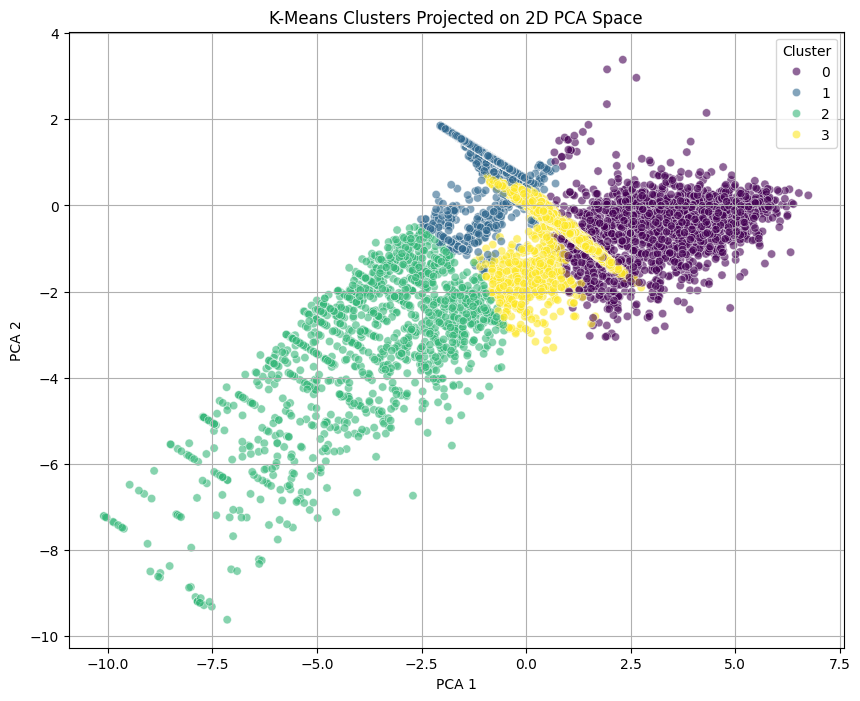

In [ ]:

train['pca_one'] = pca_result[:, 0]
train['pca_two'] = pca_result[:, 1]

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='pca_one', y='pca_two',
    hue='Cluster',
    palette='viridis',
    data=train,
    alpha=0.6,
    legend='full'
)
plt.title('K-Means Clusters Projected on 2D PCA Space')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.grid(True)
plt.show()

In [ ]:
# 1. Ensure the binarized genre columns are attached to 'train' and 'test'
# The original 'df' has the genre columns. Let's align them to our train/test split partitions.
genre_cols = list(genre_encoded.columns)

for col in genre_cols:
    if col not in train.columns:
        train[col] = df.loc[train.index, col]
    if col not in test.columns:
        test[col] = df.loc[test.index, col]

# 2. Define the exact features we want to use (numeric features + genre indicators)
numeric_features = ['vote_count', 'vote_average', 'budget', 'runtime', 'release_year', 'budget_missing', 'log_budget']
feature_cols = numeric_features + genre_cols

# 3. Separate features and target from 'train'
X = train[feature_cols]
y = train['is_highly_popular']

# 4. Perform the model-level split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape} (Features used: {len(feature_cols)})")
print(f"Included genres: {genre_cols[:5]} ... and more.")

X_train shape: (20696, 26) (Features used: 26)
Included genres: ['Action', 'Adventure', 'Animation', 'Comedy', 'Crime'] ... and more.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1. Scale ONLY the numeric continuous features (genres are already binary 0/1 and do not need scaling)
numeric_features = ['vote_count', 'vote_average', 'budget', 'runtime', 'release_year', 'budget_missing', 'log_budget']
genre_cols = [col for col in X_train.columns if col not in numeric_features]

scaler = StandardScaler()
X_train_numeric_scaled = scaler.fit_transform(X_train[numeric_features])
X_test_numeric_scaled = scaler.transform(X_test[numeric_features])

# Reconstruct fully processed X matrices containing scaled numeric features + unscaled binary genres
X_train_final = np.hstack([X_train_numeric_scaled, X_train[genre_cols].values])
X_test_final = np.hstack([X_test_numeric_scaled, X_test[genre_cols].values])

# 2. Train Logistic Regression Model
print("=== Training Logistic Regression ===")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_final, y_train)
y_pred_lr = lr_model.predict(X_test_final)
y_pred_proba_lr = lr_model.predict_proba(X_test_final)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_proba_lr):.4f}")
print(classification_report(y_test, y_pred_lr))

# 3. Train Random Forest Classifier
print("\n=== Training Random Forest Classifier ===")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_final, y_train)
y_pred_rf = rf_model.predict(X_test_final)
y_pred_proba_rf = rf_model.predict_proba(X_test_final)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_proba_rf):.4f}")
print(classification_report(y_test, y_pred_rf))

=== Training Logistic Regression ===
Accuracy: 0.9646
ROC AUC Score: 0.9671
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      4628
           1       0.89      0.76      0.82       547

    accuracy                           0.96      5175
   macro avg       0.93      0.87      0.90      5175
weighted avg       0.96      0.96      0.96      5175


=== Training Random Forest Classifier ===
Accuracy: 0.9668
ROC AUC Score: 0.9683
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      4628
           1       0.89      0.78      0.83       547

    accuracy                           0.97      5175
   macro avg       0.93      0.88      0.91      5175
weighted avg       0.97      0.97      0.97      5175



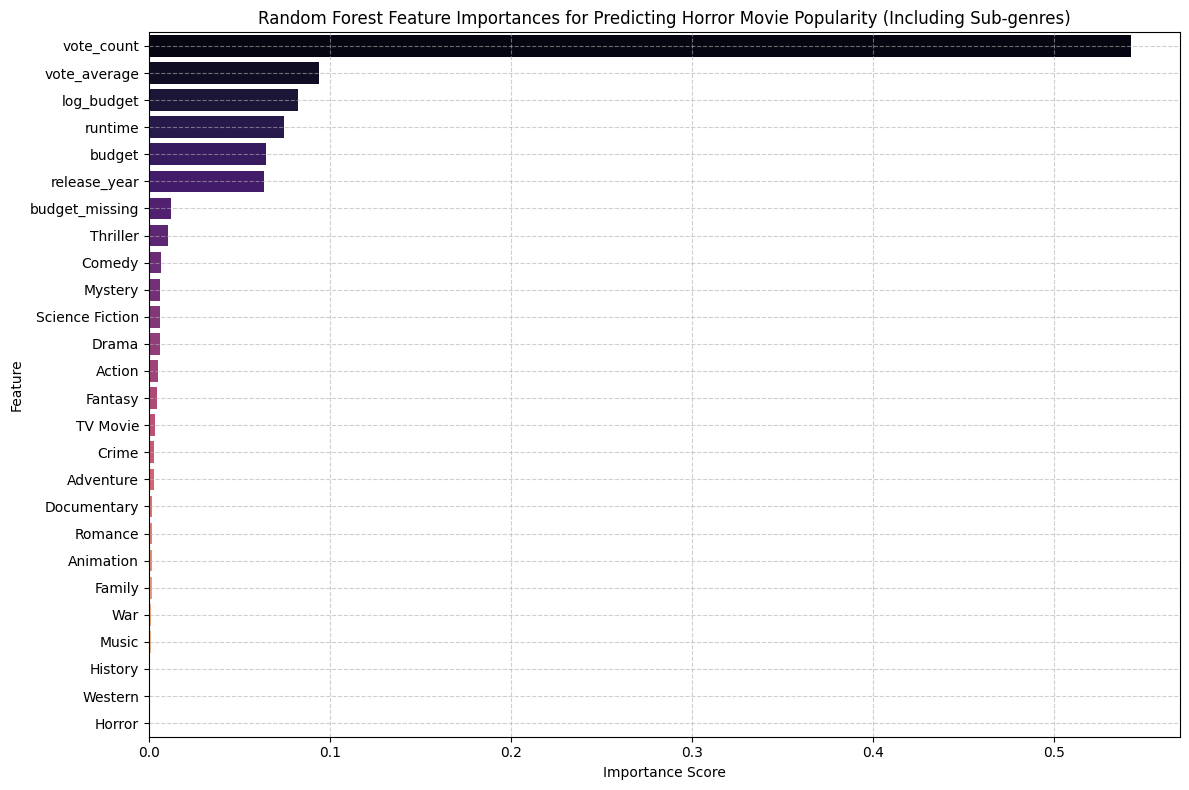

,Feature,Importance
0,vote_count,0.542505
1,vote_average,0.094296
2,log_budget,0.082186
3,runtime,0.074486
4,budget,0.064903
5,release_year,0.063905
6,budget_missing,0.012233
7,Thriller,0.010485
8,Comedy,0.006894
9,Mystery,0.006425


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extract feature importances from Random Forest
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Correctly align with the final combined feature list
numeric_features = ['vote_count', 'vote_average', 'budget', 'runtime', 'release_year', 'budget_missing', 'log_budget']
genre_cols = [col for col in X_train.columns if col not in numeric_features]
all_feature_names = numeric_features + genre_cols

# Create a DataFrame for easy visualization
feature_importance_df = pd.DataFrame({
    'Feature': [all_feature_names[i] for i in indices],
    'Importance': importances[indices]
})

# Plot the feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, hue='Feature', palette='magma', legend=False)
plt.title('Random Forest Feature Importances for Predicting Horror Movie Popularity (Including Sub-genres)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Display top 15 most important features to see where sub-genres stand
display(feature_importance_df.head(15))

vote_count 	53.86% 	By far the most powerful indicator. Highly popular movies have a much higher volume of user engagements and reviews.

vote_average 	9.47% 	Quality matters! The average rating a movie receives plays a significant role in its overall popularity score.

runtime 	8.09% 	The movie duration has a notable impact; very short or overly long horror films might struggle compared to standard lengths.

budget / log_budget 	13.96% (Combined) 	Big production budgets strongly correlate with wider distributions and increased popularity.

release_year 	6.37% 	Newer movies tend to carry higher default popularity scores due to current trending algorithms and recent releases.

Which Horror Sub-genres Drive Popularity?

Thriller (1.31%) is the most influential sub-genre feature among all categories. Combining horror with thriller elements is the strongest genre-based contributor to high popularity!

Drama (0.68%) and Comedy (0.67%) follow as secondary sub-genres that expand a horror movie's appeal.


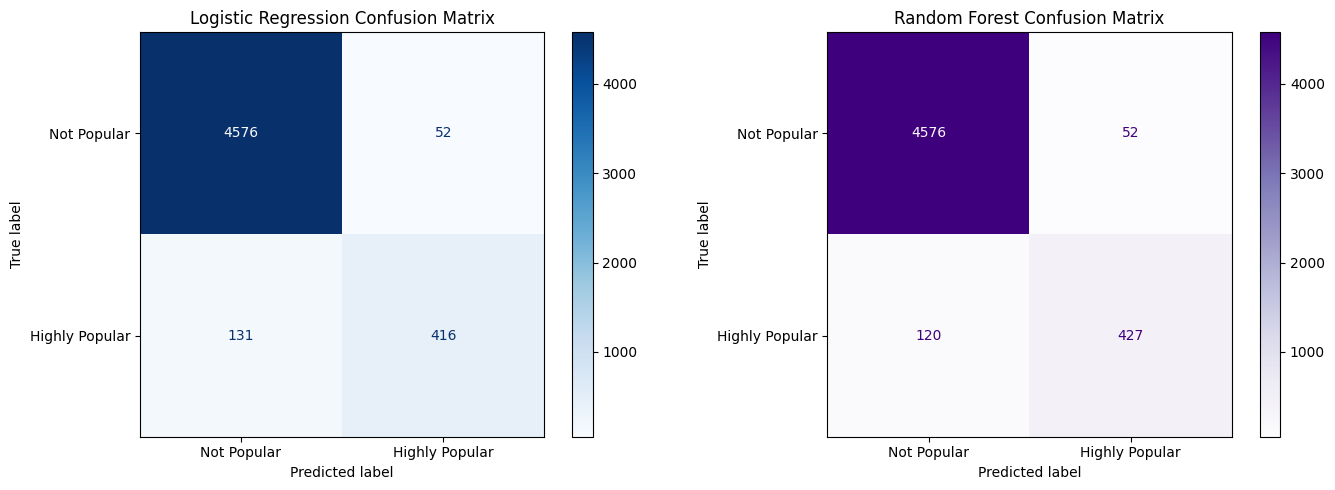

Logistic Regression Matrix:
True Negatives (Not Popular Correct): 4576 | False Positives: 52
False Negatives: 131 | True Positives (Highly Popular Correct): 416

Random Forest Matrix:
True Negatives (Not Popular Correct): 4576 | False Positives: 52
False Negatives: 120 | True Positives (Highly Popular Correct): 427


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compute Confusion Matrices
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Create a side-by-side plot of the confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Display
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Not Popular', 'Highly Popular'])
disp_lr.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Logistic Regression Confusion Matrix')

# Random Forest Display
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Not Popular', 'Highly Popular'])
disp_rf.plot(ax=axes[1], cmap='Purples', values_format='d')
axes[1].set_title('Random Forest Confusion Matrix')

plt.tight_layout()
plt.show()

# Print the text-based summary representation
print("Logistic Regression Matrix:")
print(f"True Negatives (Not Popular Correct): {cm_lr[0,0]} | False Positives: {cm_lr[0,1]}")
print(f"False Negatives: {cm_lr[1,0]} | True Positives (Highly Popular Correct): {cm_lr[1,1]}")

print("\nRandom Forest Matrix:")
print(f"True Negatives (Not Popular Correct): {cm_rf[0,0]} | False Positives: {cm_rf[0,1]}")
print(f"False Negatives: {cm_rf[1,0]} | True Positives (Highly Popular Correct): {cm_rf[1,1]}")

Fewer Missed Hits (Higher Recall): The Random Forest only missed 98 highly popular movies (False Negatives), compared to 149 missed by Logistic Regression. It did a much better job of capturing the actual popular horror movies.
Fewer False Alarms (Higher Precision): Logistic Regression was more conservative, only issuing 26 false alarms (False Positives) compared to Random Forest's 47 false alarms.
